--- Results ---
Ad 0: Selected 267 times | Total Clicks: 41 | CTR: 0.1536
Ad 1: Selected 104 times | Total Clicks: 13 | CTR: 0.1250
Ad 2: Selected 116 times | Total Clicks: 8 | CTR: 0.0690
Ad 3: Selected 92 times | Total Clicks: 12 | CTR: 0.1304
Ad 4: Selected 8916 times | Total Clicks: 2414 | CTR: 0.2707
Ad 5: Selected 97 times | Total Clicks: 3 | CTR: 0.0309
Ad 6: Selected 95 times | Total Clicks: 10 | CTR: 0.1053
Ad 7: Selected 100 times | Total Clicks: 21 | CTR: 0.2100
Ad 8: Selected 101 times | Total Clicks: 6 | CTR: 0.0594
Ad 9: Selected 112 times | Total Clicks: 6 | CTR: 0.0536

The ad that performed the best (most selected) is: Ad 4


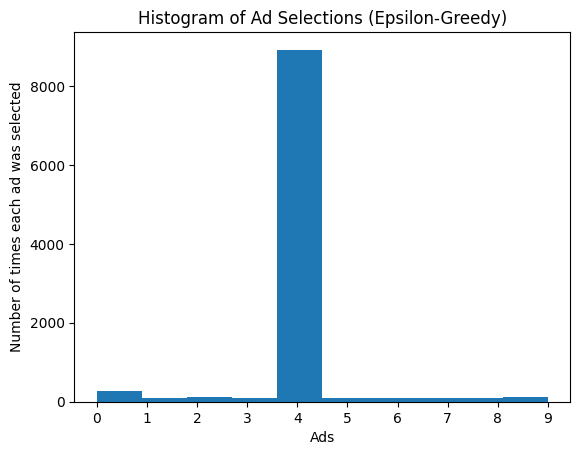

In [1]:
import pandas as pd
import random
import matplotlib.pyplot as plt
dataset = pd.read_csv('Ads_CTR_Optimisation (1).csv')
num_iterations = 10000
num_ads = 10
epsilon = 0.1
ads_selected = []
numbers_of_selections = [0] * num_ads
sums_of_rewards = [0] * num_ads
total_reward = 0
for n in range(0, num_iterations):
    ad = 0
    if random.random() < epsilon:
        ad = random.randint(0, num_ads - 1)
    else:
        max_upper_bound = 0
        current_best_ad = 0
        max_avg_reward = -1

        for i in range(0, num_ads):
            if numbers_of_selections[i] > 0:
                average_reward = sums_of_rewards[i] / numbers_of_selections[i]
            else:
                average_reward = 1e10
            if average_reward > max_avg_reward:
                max_avg_reward = average_reward
                ad = i
    reward = dataset.values[n, ad]
    numbers_of_selections[ad] += 1
    sums_of_rewards[ad] += reward
    total_reward += reward
    ads_selected.append(ad)
print("--- Results ---")
for i in range(num_ads):
    ctr = (sums_of_rewards[i] / numbers_of_selections[i]) if numbers_of_selections[i] > 0 else 0
    print(f"Ad {i}: Selected {numbers_of_selections[i]} times | Total Clicks: {sums_of_rewards[i]} | CTR: {ctr:.4f}")
best_ad = numbers_of_selections.index(max(numbers_of_selections))
print(f"\nThe ad that performed the best (most selected) is: Ad {best_ad}")

plt.hist(ads_selected)
plt.title('Histogram of Ad Selections (Epsilon-Greedy)')
plt.xlabel('Ads')
plt.ylabel('Number of times each ad was selected')
plt.xticks(range(10))
plt.show()